In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])
print("Feature names:", data.feature_names)
print("Classes:", data.target_names)

Dataset shape: (569, 30)
Target shape: (569,)
Number of features: 30
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Classes: ['malignant' 'benign']


In [2]:
breast_dataset = pd.DataFrame(
    X, columns=data.feature_names
)

breast_dataset["label"] = y

breast_dataset["label"] = breast_dataset["label"].map({
    0: "Malignant",
    1: "Benign"
})

display(breast_dataset.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


In [3]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

print("Standardized shape:", X_std.shape)
print("Mean of first five features:",
      np.round(X_std.mean(axis=0)[:5], 4))
print("Standard deviation of first five features:",
      np.round(X_std.std(axis=0)[:5], 4))

Standardized shape: (569, 30)
Mean of first five features: [-0. -0. -0. -0.  0.]
Standard deviation of first five features: [1. 1. 1. 1. 1.]


In [4]:
cov_mat = np.cov(X_std.T)

print("Covariance matrix shape:", cov_mat.shape)
print("First 5 rows and columns:")
print(np.round(cov_mat[:5, :5], 3))

Covariance matrix shape: (30, 30)
First 5 rows and columns:
[[ 1.002  0.324  1.     0.989  0.171]
 [ 0.324  1.002  0.33   0.322 -0.023]
 [ 1.     0.33   1.002  0.988  0.208]
 [ 0.989  0.322  0.988  1.002  0.177]
 [ 0.171 -0.023  0.208  0.177  1.002]]


In [5]:
eig_vals, eig_vecs = np.linalg.eigh(cov_mat)

# Sort eigenvalues and eigenvectors in descending order
idx = np.argsort(eig_vals)[::-1]

eig_vals = eig_vals[idx]
eig_vecs = eig_vecs[:, idx]

print("Eigenvalues shape:", eig_vals.shape)
print("Eigenvectors shape:", eig_vecs.shape)
print("First five eigenvalues:")
print(eig_vals[:5])

Eigenvalues shape: (30,)
Eigenvectors shape: (30, 30)
First five eigenvalues:
[13.30499079  5.7013746   2.82291016  1.98412752  1.65163324]


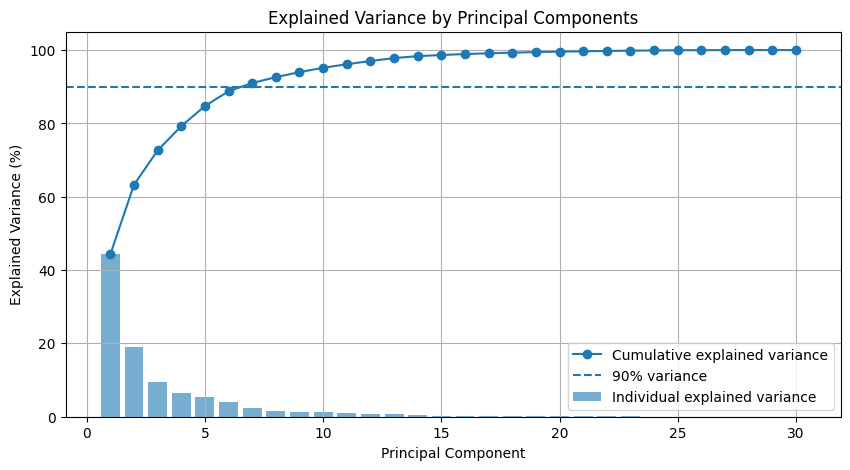

In [6]:
explained_variance = eig_vals / eig_vals.sum() * 100
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.6,
    label="Individual explained variance"
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    label="Cumulative explained variance"
)

plt.axhline(90, linestyle="--", label="90% variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance by Principal Components")
plt.legend()
plt.grid()
plt.show()

In [7]:
n_components_90 = np.argmax(cumulative_variance >= 90) + 1

print("Variance explained by each component:")
print(np.round(explained_variance, 2))

print("\nCumulative variance:")
print(np.round(cumulative_variance, 2))

print("\nComponents required for 90% variance:",
      n_components_90)

print("Variance retained:",
      round(cumulative_variance[n_components_90 - 1], 2), "%")

Variance explained by each component:
[4.427e+01 1.897e+01 9.390e+00 6.600e+00 5.500e+00 4.020e+00 2.250e+00
 1.590e+00 1.390e+00 1.170e+00 9.800e-01 8.700e-01 8.000e-01 5.200e-01
 3.100e-01 2.700e-01 2.000e-01 1.800e-01 1.600e-01 1.000e-01 1.000e-01
 9.000e-02 8.000e-02 6.000e-02 5.000e-02 3.000e-02 2.000e-02 1.000e-02
 0.000e+00 0.000e+00]

Cumulative variance:
[ 44.27  63.24  72.64  79.24  84.73  88.76  91.01  92.6   93.99  95.16
  96.14  97.01  97.81  98.34  98.65  98.92  99.11  99.29  99.45  99.56
  99.66  99.75  99.83  99.89  99.94  99.97  99.99 100.   100.   100.  ]

Components required for 90% variance: 7
Variance retained: 91.01 %


In [8]:
pca_3 = PCA(n_components=3)
Y_3 = pca_3.fit_transform(X_std)

print("Original data shape:", X_std.shape)
print("Reduced data shape:", Y_3.shape)

print("Variance explained by 3 components:",
      round(pca_3.explained_variance_ratio_.sum() * 100, 2), "%")

Original data shape: (569, 30)
Reduced data shape: (569, 3)
Variance explained by 3 components: 72.64 %


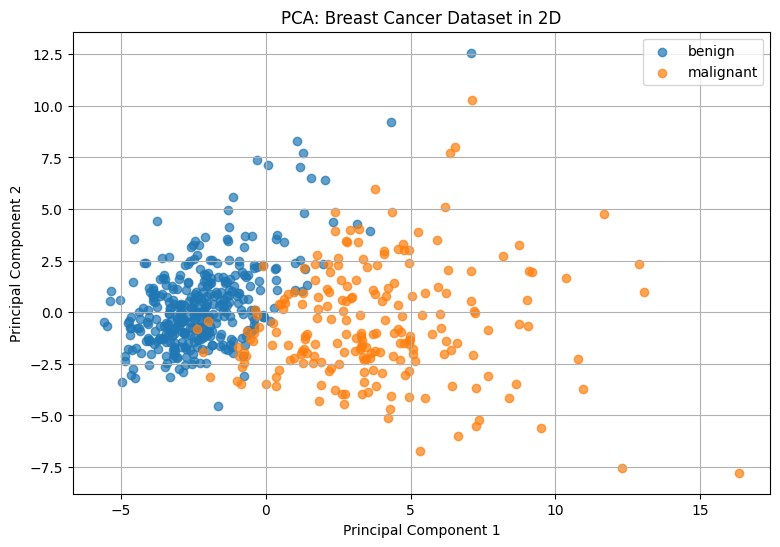

In [9]:
pca_2 = PCA(n_components=2)
Y_2 = pca_2.fit_transform(X_std)

labels = data.target_names[y]

plt.figure(figsize=(9, 6))

for label in np.unique(labels):
    mask = labels == label
    plt.scatter(
        Y_2[mask, 0],
        Y_2[mask, 1],
        label=label,
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Breast Cancer Dataset in 2D")
plt.legend()
plt.grid()
plt.show()

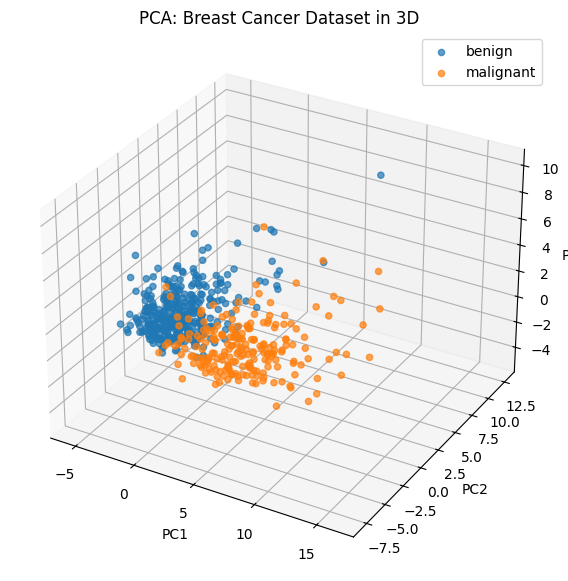

In [10]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

for label in np.unique(labels):
    mask = labels == label
    ax.scatter(
        Y_3[mask, 0],
        Y_3[mask, 1],
        Y_3[mask, 2],
        label=label,
        alpha=0.7
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("PCA: Breast Cancer Dataset in 3D")
ax.legend()
plt.show()

In [11]:
print("Original number of features:", X.shape[1])
print("Features using 2 PCs:", Y_2.shape[1])
print("Features using 3 PCs:", Y_3.shape[1])
print("Features needed for 90% variance:", n_components_90)

print("\nVariance retained using 2 PCs:",
      round(pca_2.explained_variance_ratio_.sum() * 100, 2), "%")

print("Variance retained using 3 PCs:",
      round(pca_3.explained_variance_ratio_.sum() * 100, 2), "%")

pca_90 = PCA(n_components=0.90)
Y_90 = pca_90.fit_transform(X_std)

print("Reduced shape for 90% variance:", Y_90.shape)
print("Actual variance retained:",
      round(pca_90.explained_variance_ratio_.sum() * 100, 2), "%")

Original number of features: 30
Features using 2 PCs: 2
Features using 3 PCs: 3
Features needed for 90% variance: 7

Variance retained using 2 PCs: 63.24 %
Variance retained using 3 PCs: 72.64 %
Reduced shape for 90% variance: (569, 7)
Actual variance retained: 91.01 %


Question 1: How many components are needed to retain 90% of the variance?

The number of principal components required is printed in Cell 7. PCA calculates the explained variance of each component and adds the values cumulatively. We retain the smallest number of components for which cumulative explained variance reaches or exceeds 90%.


Question 2: Find another real-world use case of PCA and explain its application.
Application:
Face recognition
Face images contain many pixel values, making them high-dimensional data. PCA can reduce these dimensions by identifying the main patterns of variation across face images. The reduced representation retains important facial information while removing some less significant variation.

A face-recognition system can then use these reduced representations as inputs to a classification or recognition algorithm. This can reduce storage requirements and computational cost.


Why is PCA useful before training machine-learning models?

PCA reduces the number of features while preserving as much variation in the data as possible. In this breast-cancer dataset, the original 30 features can be projected into two or three principal components for visualization. Reducing dimensionality can lower computational cost and sometimes help reduce overfitting, although PCA does not guarantee better predictive accuracy. The principal components are combinations of the original features, so they can also be less directly interpretable.